# This is all just the bulk data, which we decided isn't useful

In [3]:
# conda env 'spec'
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path().resolve().parent.parent.parent
sys.path.append(str(PROJECT_ROOT))

In [4]:
from src.CAMP2Ex import load_p3

In [23]:
RAW_DATA = PROJECT_ROOT / 'data' / 'raw'
bulk_props_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'CAMP2Ex-CloudBulkProps_P3B_20191001_R0.ICT'
nav_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'CAMP2EX-MetNav_P3B_20191001_R0.ict'

p3_all = load_p3(bulk_props_file, nav_file, CP_Type_accept=[1, 2, 3])
p3_all['Sat_Mixing_Ratio_H2O'] = (0.622 * p3_all['Sat_Vapor_Press_H2O']) / (p3_all['Static_Pressure'] - p3_all['Sat_Vapor_Press_H2O'])
p3_all['Sat_Mixing_Ratio_H2O_CB'] = 0.0194
Rd = 287 # J kg^-1 K^-1
p3_all['Density_Dry_Air'] = (100*p3_all['Static_Pressure']) / (Rd * (p3_all['Static_Air_Temp']+273.15)) # kg m^-3
p3_all['ALWC_gm3'] = 1000 * (p3_all['Sat_Mixing_Ratio_H2O_CB'] - p3_all['Sat_Mixing_Ratio_H2O']) * p3_all['Density_Dry_Air']
p3_all['pct_ALWC'] = p3_all['LWC_gm3'] / p3_all['ALWC_gm3']
p3_cloud = p3_all[p3_all['cloud_pass'] > 0]

p3_agg = p3_cloud.reset_index().groupby('cloud_pass').agg(
    start_time=('datetime', 'min'),
    end_time=('datetime', 'max'),
    pass_length=('Ground_Speed', 'sum'),
    altitude=('GPS_Altitude', 'mean'),
    pct_CP_1_cloud=('CP_Type', lambda x: 100*(x == 1).sum() / len(x)),
    pct_CP_2_precip=('CP_Type', lambda x: 100*(x == 2).sum() / len(x)),
    pct_CP_3_scud=('CP_Type', lambda x: 100*(x == 3).sum() / len(x)),
    mean_ext_km=('ext_km', 'mean'),
    min_ext_km=('ext_km', 'min'),
    max_ext_km=('ext_km', 'max'),
    mean_LWC_gm3=('LWC_gm3', 'mean'),
    min_LWC_gm3=('LWC_gm3', 'min'),
    max_LWC_gm3=('LWC_gm3', 'max'),
    mean_Reff_um=('Reff_um', 'mean'),
    min_Reff_um=('Reff_um', 'min'),
    max_Reff_um=('Reff_um', 'max')
)
# p3_agg


<Axes: xlabel='pct_ALWC', ylabel='GPS_Altitude'>

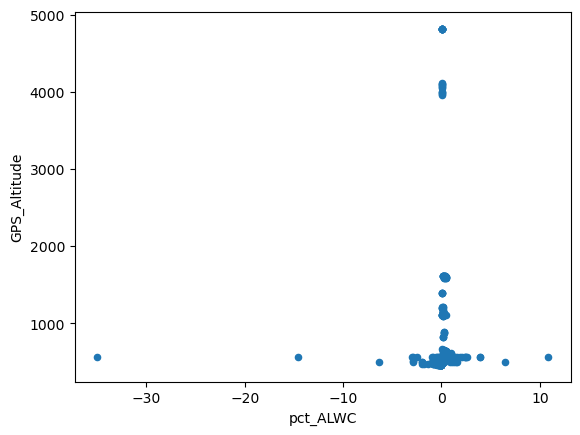

In [25]:
p3_cloud.plot.scatter(x='pct_ALWC', y='GPS_Altitude')

<Axes: xlabel='LWC_gm3', ylabel='GPS_Altitude'>

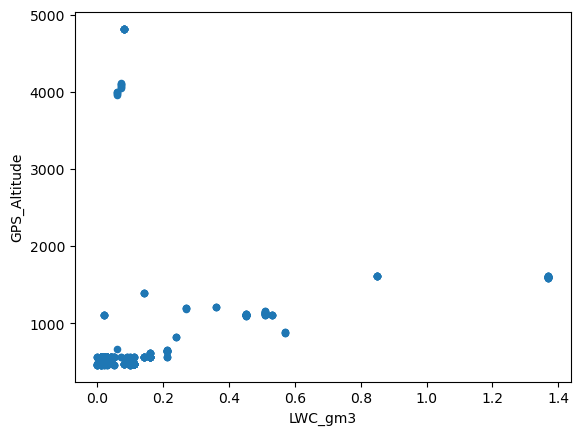

In [21]:
p3_cloud.plot.scatter(x='LWC_gm3', y='GPS_Altitude')

<Axes: xlabel='ALWC_gm3', ylabel='GPS_Altitude'>

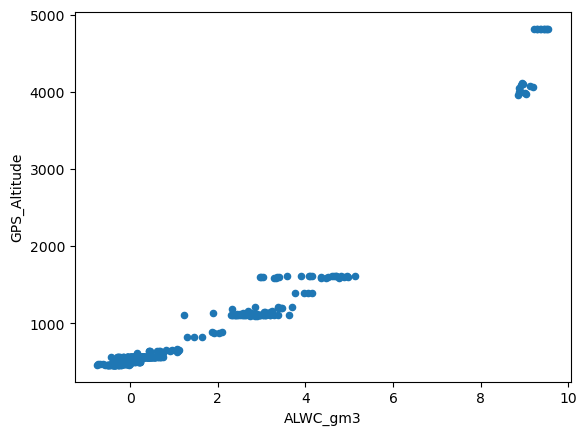

In [20]:
p3_cloud.plot.scatter(x='ALWC_gm3', y='GPS_Altitude')

<Axes: xlabel='Sat_Mixing_Ratio_H2O', ylabel='GPS_Altitude'>

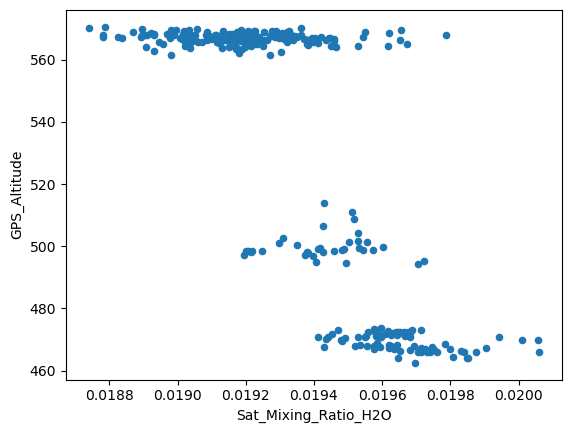

In [17]:
p3_cloud[p3_cloud['GPS_Altitude'] < 600].plot.scatter(x='Sat_Mixing_Ratio_H2O', y='GPS_Altitude')

<Axes: xlabel='Sat_Mixing_Ratio_H2O', ylabel='GPS_Altitude'>

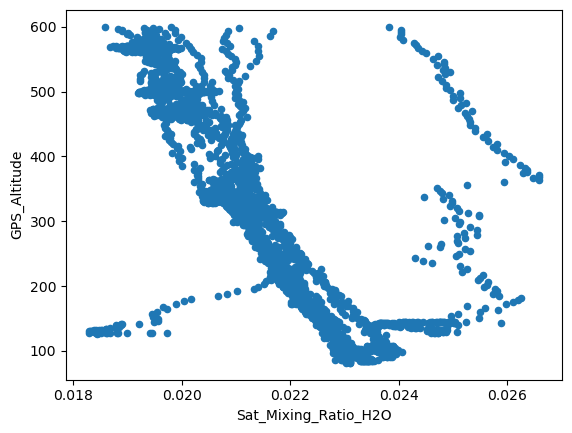

In [14]:
p3_all[p3_all['GPS_Altitude'] < 600].plot.scatter(x='Sat_Mixing_Ratio_H2O', y='GPS_Altitude')

<Axes: xlabel='LWC_gm3', ylabel='GPS_Altitude'>

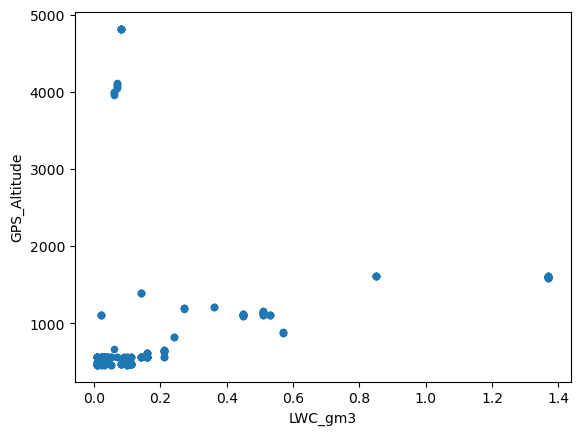

In [7]:
p3_all[p3_all['LWC_gm3'] > 0].plot.scatter(x='LWC_gm3', y='GPS_Altitude')

In [ ]:
p3_all['']

In [ ]:
p3_agg[p3_agg['altitude'] <= 1250].plot.scatter(x='mean_ext_km', y='altitude', c='pct_CP_1_cloud', vmin=0, vmax=100)

In [5]:
# Source - https://stackoverflow.com/a
# Posted by Fons
# Retrieved 2025-11-07, License - CC BY-SA 4.0

def legend_without_duplicate_labels(ax, ncol=None):
    handles, labels = ax.get_legend_handles_labels()
    unique = [(h, l) for i, (h, l) in enumerate(zip(handles, labels)) if l not in labels[:i]]
    ax.legend(ncol=ncol, *zip(*unique))

def plot_p3(start_time, end_time, p3_agg, p3_all, agg_attrs, all_attrs, legend=True, savedir=None):
    plt.style.use('seaborn-v0_8-talk')
    p3agg_subset = p3_agg[
        (p3_agg['end_time'] >= start_time)
        & (p3_agg['start_time'] <= end_time)
        # & (p3_agg['altitude'] <= 1250)
    ]
    p3_subset = p3_all[
        (p3_all.index >= start_time)
        & (p3_all.index <= end_time)
    ]
    nrows = len(agg_attrs) + len(all_attrs)
    if(len(p3agg_subset) > 0):
        f, ax = plt.subplots(nrows, 1, figsize=(14,nrows*3.3), sharex=True)
        for pass_number, row in p3agg_subset.iterrows():
            for i, attr in enumerate(agg_attrs):
                ax[i].plot(
                    [row['start_time'], row['end_time']],
                    [row[f'mean_{attr}'], row[f'mean_{attr}']], 
                    label=f'pass {pass_number}',
                    ls='-',
                    lw=3
                )
                # ax[i].vlines(
                #     [row['start_time'], row['end_time']], 
                #     ymin=row[f'min_{attr}'], 
                #     ymax=row[f'max_{attr}'],
                #     colors='k',
                #     linestyles='dashed',
                #     lw=0.5
                # )
                ax[i].set_ylabel(attr)
        for j, attr in enumerate(all_attrs):
            if(attr != 'CP_Type'):
                ax[i+j+1].plot(p3_subset.index, p3_subset[attr], 'k')
            ax[i+j+1].set_ylabel(attr)

        scatter_kwargs = {
            'c':'k',
            # 's':16,
            'marker':'o',
        }
        for pass_number, row in p3agg_subset.iterrows():
            p3_tmp = p3_all[
                (p3_all.index >= row['start_time'])
                & (p3_all.index <= row['end_time'])
            ]
            for i, attr in enumerate(agg_attrs):
                ax[i].scatter(p3_tmp.index, p3_tmp[attr], **scatter_kwargs)
                # t1 = p3_tmp[p3_tmp['CP_Type'] == 1]
                # t2 = p3_tmp[p3_tmp['CP_Type'] == 2]
                # t3 = p3_tmp[p3_tmp['CP_Type'] == 3]
                # ax[i].scatter(t1.index, t1[attr], c='grey', label='CP Type 1: Cloud', **scatter_kwargs)
                # ax[i].scatter(t2.index, t2[attr], c='black', label='CP Type 2: Precip', **scatter_kwargs)
                # ax[i].scatter(t3.index, t3[attr], c='blue', label='CP Type 3: Scud', **scatter_kwargs)
            for j, attr in enumerate(all_attrs):
                if(attr == 'CP_Type'):
                    ax[i+j+1].scatter(p3_tmp.index, p3_tmp[attr])
                else:
                    ax[i+j+1].plot(p3_tmp.index, p3_tmp[attr], lw=5)

        title = f'{str(start_time)}_{str(end_time)}'
        ax[0].set_title(title)
        for a in ax:
            a.grid()
        if(legend):
            legend_without_duplicate_labels(ax[0], ncol=2)
        if(savedir):
            savedir.mkdir(exist_ok=True, parents=True)
            plt.savefig(
                savedir / '{}.png'.format(title),
                format='png',
                dpi=300,
                bbox_inches='tight',
                transparent=False
            )
            plt.close(f)


In [6]:
FIG_DIR = Path().resolve() / 'CAMP2Ex_insitu2'

In [10]:
# ## Large Extinction 1-4
# savedir = FIG_DIR / 'LargeExtinction'
# agg_attrs = ['ext_km']
# all_attrs = ['CP_Type', 'GPS_Altitude', 'Latitude', 'Longitude']

# start_time = pd.to_datetime('2019-10-02 00:35:20')
# end_time = pd.to_datetime('2019-10-02 00:35:40')
# plot_p3(start_time, end_time, p3_agg, p3_all, agg_attrs, all_attrs, legend=False, savedir=savedir)

# start_time = pd.to_datetime('2019-10-02 01:43:25')
# end_time = pd.to_datetime('2019-10-02 01:43:45')
# plot_p3(start_time, end_time, p3_agg, p3_all, agg_attrs, all_attrs, legend=False, savedir=savedir)

# start_time = pd.to_datetime('2019-10-02 01:45:25')
# end_time = pd.to_datetime('2019-10-02 01:46:10')
# plot_p3(start_time, end_time, p3_agg, p3_all, agg_attrs, all_attrs, legend=False, savedir=savedir)

# start_time = pd.to_datetime('2019-10-02 01:49:20')
# end_time = pd.to_datetime('2019-10-02 01:49:40')
# plot_p3(start_time, end_time, p3_agg, p3_all, agg_attrs, all_attrs, legend=False, savedir=savedir)

In [8]:
# ## Full Range
# savedir = FIG_DIR / 'FullRange'
# start_time = pd.to_datetime('2019-10-02 00:00:00')
# end_time = pd.to_datetime('2019-10-02 02:00:00')
# agg_attrs = ['ext_km']
# all_attrs = ['CP_Type', 'GPS_Altitude', 'Latitude', 'Longitude']
# plot_p3(start_time, end_time, p3_agg, p3_all, agg_attrs, all_attrs, legend=False, savedir=savedir)

In [9]:
# ## Typical data
# savedir = FIG_DIR / 'TypicalData'
# agg_attrs = ['ext_km']
# all_attrs = ['CP_Type', 'GPS_Altitude', 'Latitude', 'Longitude']

# start_time = pd.to_datetime('2019-10-02 00:21:00')
# end_time = pd.to_datetime('2019-10-02 00:28:10')
# plot_p3(start_time, end_time, p3_agg, p3_all, agg_attrs, all_attrs, legend=False, savedir=savedir)

# start_time = pd.to_datetime('2019-10-02 01:31:00')
# end_time = pd.to_datetime('2019-10-02 01:40:10')
# plot_p3(start_time, end_time, p3_agg, p3_all, agg_attrs, all_attrs, legend=False, savedir=savedir)

# start_time = pd.to_datetime('2019-10-02 01:38:30')
# end_time = pd.to_datetime('2019-10-02 01:40:10')
# plot_p3(start_time, end_time, p3_agg, p3_all, agg_attrs, all_attrs, legend=False, savedir=savedir)

In [11]:
# ## P3 Forward Videos: 7 min interval
# base_time = pd.to_datetime('2019-10-01 23:59:26')
# window = 15
# interval = 7
# delta_t = pd.Timedelta(window, unit='min')
# interval_t = pd.Timedelta(interval, unit='min')
# agg_attrs = ['ext_km']
# all_attrs = ['GPS_Altitude', 'Latitude', 'Longitude']
# savedir = FIG_DIR / f'Window_{window}min_Interval_{interval}min'
# for i in range((120 // interval)+1):
#     start_time = base_time + i * interval_t
#     end_time = start_time + delta_t
#     plot_p3(
#         start_time,
#         end_time,
#         p3_agg,
#         p3_all,
#         agg_attrs,
#         all_attrs,
#         legend=False,
#         savedir=savedir
#     )

In [12]:
# ## P3 Forward Videos: 15 min interval
# base_time = pd.to_datetime('2019-10-01 23:59:26')
# window = 15
# interval = 15
# delta_t = pd.Timedelta(window, unit='min')
# interval_t = pd.Timedelta(interval, unit='min')
# agg_attrs = ['ext_km']
# all_attrs = ['GPS_Altitude', 'Latitude', 'Longitude']
# savedir = FIG_DIR / f'Window_{window}min_Interval_{interval}min'
# for i in range((120 // interval)+1):
#     start_time = base_time + i * interval_t
#     end_time = start_time + delta_t
#     plot_p3(
#         start_time,
#         end_time,
#         p3_agg,
#         p3_all,
#         agg_attrs,
#         all_attrs,
#         legend=False,
#         savedir=savedir
#     )

In [13]:
# ## 3 min window | 1 min interval
# base_time = pd.to_datetime('2019-10-02 00:00:00')
# window = 3
# interval = 1
# delta_t = pd.Timedelta(window, unit='min')
# interval_t = pd.Timedelta(interval, unit='min')
# agg_attrs = ['ext_km']
# all_attrs = ['CP_Type', 'GPS_Altitude', 'Latitude', 'Longitude']
# savedir = FIG_DIR / f'Window_{window}min_Interval_{interval}min'
# for i in range((120 // interval)+1):
#     start_time = base_time + i * interval_t
#     end_time = start_time + delta_t
#     plot_p3(
#         start_time,
#         end_time,
#         p3_agg,
#         p3_all,
#         agg_attrs,
#         all_attrs,
#         legend=False,
#         savedir=savedir
#     )